# Proyecto: predicción de recaída en depresión

Hice este cuaderno para practicar un poco de Python y machine learning. Uso datos inventados de 300 pacientes y trato de predecir si van a recaer en 6 meses.

Nota: los datos son ficticios. El PHQ-9 es un cuestionario de cribado, no un diagnóstico.

In [1]:
# importo las librerías que voy a usar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

## Datos

Inventé 300 pacientes. La columna `recaida_6m` dice si recayeron (1) o no (0).

In [2]:
# fijo la semilla para que los datos salgan iguales siempre
np.random.seed(42)

n = 300
datos = pd.DataFrame({
    'edad': np.random.randint(18, 71, n),
    'sexo_femenino': np.random.randint(0, 2, n),
    'phq9_alta': np.random.randint(0, 10, n),
    'episodios_previos': np.random.randint(0, 6, n),
    'adherencia': np.random.randint(0, 11, n),
    'apoyo_social': np.random.randint(0, 11, n),
    'horas_sueno': np.random.uniform(4, 9, n).round(1)
})

# calculo un puntaje de riesgo para decidir quién recae
riesgo = (0.8 * datos['phq9_alta'] + 0.6 * datos['episodios_previos']
          - 0.5 * datos['adherencia'] - 0.4 * datos['apoyo_social']
          - 0.3 * (datos['horas_sueno'] - 6) + np.random.normal(0, 2, n))

# marco como recaída al 20% con más riesgo
datos['recaida_6m'] = (riesgo > np.quantile(riesgo, 0.8)).astype(int)

datos.head()

,edad,sexo_femenino,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno,recaida_6m
0,56,1,9,2,7,2,8.3,0
1,69,0,9,0,3,3,9.0,0
2,46,1,4,4,7,10,7.4,0
3,32,1,6,4,7,0,6.2,1
4,60,1,3,3,4,10,7.2,0


recaida_6m
0    240
1     60
Name: count, dtype: int64


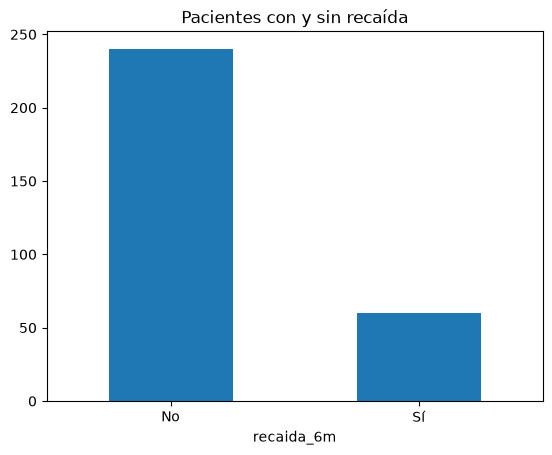

In [3]:
# veo cuántos pacientes hay en cada clase
print(datos['recaida_6m'].value_counts())

# hago un gráfico rápido
datos['recaida_6m'].value_counts().plot(kind='bar')
plt.title('Pacientes con y sin recaída')
plt.xticks([0, 1], ['No', 'Sí'], rotation=0)
plt.show()

## Revisión rápida

Antes de entrenar, miro si los promedios cambian entre los que recayeron y los que no.

In [4]:
# comparo los promedios de algunas variables
promedios = datos.groupby('recaida_6m')[
    ['phq9_alta', 'episodios_previos', 'adherencia', 'apoyo_social', 'horas_sueno']
].mean()
promedios.round(2)

,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno
recaida_6m,,,,,
0,3.75,2.42,5.42,5.65,6.66
1,6.88,3.12,3.12,3.38,6.12


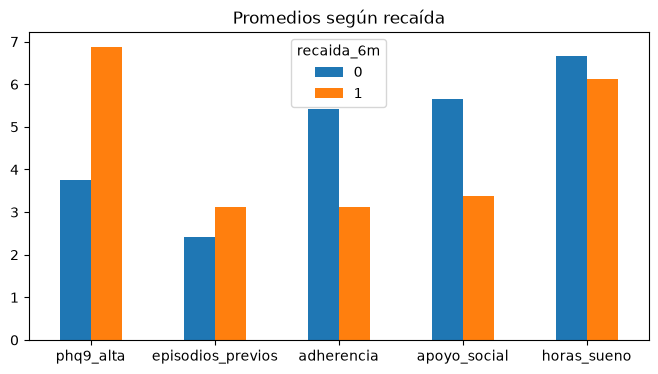

In [5]:
# hago un gráfico para comparar mejor
promedios.T.plot(kind='bar', figsize=(8, 4))
plt.title('Promedios según recaída')
plt.xticks(rotation=0)
plt.show()

## Modelo

Separo los datos y entreno una regresión logística.

In [6]:
# separo las variables que uso para predecir
X = datos.drop(columns='recaida_6m')
y = datos['recaida_6m']

# divido los datos: 80% para entrenar y 20% para probar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# escalo las variables para que estén en una escala parecida
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

# entreno el modelo
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_esc, y_train)

# hago las predicciones
pred = modelo.predict(X_test_esc)
proba = modelo.predict_proba(X_test_esc)[:, 1]

## Resultados

In [7]:
# calculo las métricas
print('Exactitud:', round(accuracy_score(y_test, pred), 2))
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 2))
print('Matriz de confusión:')
print(confusion_matrix(y_test, pred))

Exactitud: 0.87
ROC-AUC: 0.91
Matriz de confusión:
[[44  4]
 [ 4  8]]


El modelo acert? el 87% y el ROC-AUC fue 0.91. En la matriz de confusi?n se ven 8 reca?das detectadas y 4 que se me escaparon.

In [8]:
# miro qué variables pesan más
coeficientes = pd.Series(modelo.coef_[0], index=X.columns).sort_values()
coeficientes.round(2)

adherencia          -1.14
apoyo_social        -0.89
horas_sueno         -0.45
edad                -0.25
sexo_femenino       -0.04
episodios_previos    0.89
phq9_alta            1.69
dtype: float64

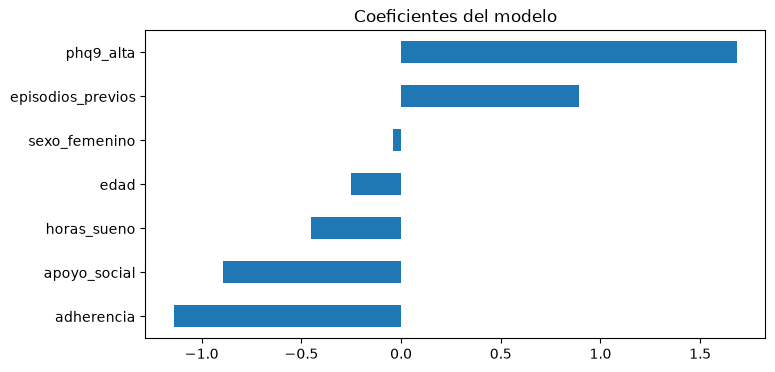

In [9]:
# grafico los coeficientes
coeficientes.plot(kind='barh', figsize=(8, 4))
plt.title('Coeficientes del modelo')
plt.show()

## Prueba con dos pacientes

Al final pruebo el modelo con dos pacientes inventados.

In [10]:
# creo dos pacientes de ejemplo
nuevo = pd.DataFrame({
    'edad': [35, 52],
    'sexo_femenino': [1, 0],
    'phq9_alta': [8, 3],
    'episodios_previos': [4, 1],
    'adherencia': [4, 9],
    'apoyo_social': [3, 8],
    'horas_sueno': [5.5, 7.5]
})

# escalo los datos con el mismo escalador
nuevo_esc = escalador.transform(nuevo)

# calculo la probabilidad de recaída
nuevo['riesgo'] = modelo.predict_proba(nuevo_esc)[:, 1].round(2)

# lo clasifico con un umbral de 0.5
nuevo['resultado'] = np.where(nuevo['riesgo'] >= 0.5, 'Riesgo alto', 'Riesgo bajo')
nuevo

,edad,sexo_femenino,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno,riesgo,resultado
0,35,1,8,4,4,3,5.5,0.82,Riesgo alto
1,52,0,3,1,9,8,7.5,0.00,Riesgo bajo


## Conclusión

El modelo logra separar bastante bien los pacientes que recaen de los que no, aunque todavía se le escapan varias recaídas. Fue un ejercicio para practicar clasificación con regresión logística usando datos inventados.